
Leakage demo (scaler fit before vs after split); StratifiedKFold vs KFold comparison; nested CV optimism bias; full_cv_report() function

Dataset shape: (569, 30)
Class distribution:
0    212
1    357
Name: count, dtype: int64

DATA LEAKAGE COMPARISON
Accuracy with leakage: 0.9825
Accuracy with correct scaling: 0.9825

Note: leakage does not always increase accuracy.
The correct approach is to fit preprocessing on training data only.

KFOLD SCORES: [0.9737 0.9825 0.9649 0.9912 0.9735]
KFOLD MEAN: 0.9771
KFOLD STD: 0.009

STRATIFIED KFOLD SCORES: [0.9737 0.9474 0.9649 0.9912 0.9912]
STRATIFIED KFOLD MEAN: 0.9737
STRATIFIED KFOLD STD: 0.0166


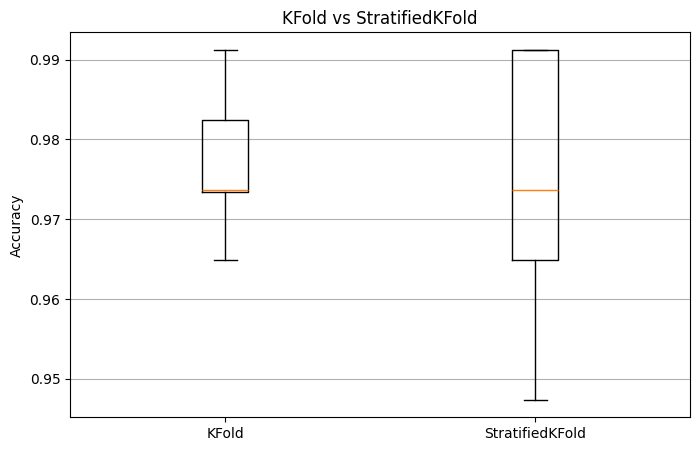


NESTED CROSS-VALIDATION
Best parameter: {'classifier__C': 0.1}
Non-nested best CV score: 0.9737
Nested CV scores: [0.9649 0.9474 0.9912 1.     0.9823]
Nested CV mean: 0.9772
Nested CV std: 0.0189
Observed score difference: -0.0035

The difference illustrates possible selection optimism.
It can be positive, negative, or near zero.

FULL CROSS-VALIDATION REPORT
   Metric   Mean  Standard Deviation
 Accuracy 0.9737              0.0166
Precision 0.9683              0.0290
   Recall 0.9916              0.0112
       F1 0.9794              0.0127


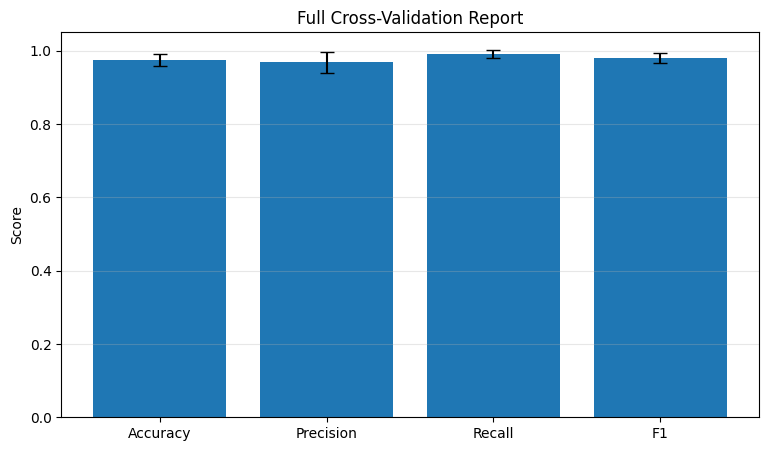


ALL CROSS-VALIDATION EXPERIMENTS COMPLETED!


In [ ]:

# ============================================================
# CROSS-VALIDATION PRACTICAL
# Leakage Demo + StratifiedKFold vs KFold + Nested CV
# + full_cv_report() Function
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import (
    train_test_split,
    KFold,
    StratifiedKFold,
    cross_validate,
    GridSearchCV,
    cross_val_score
)
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score


# ------------------------------------------------------------
# 1. LOAD DATASET
# ------------------------------------------------------------

data = load_breast_cancer()
X = data.data
y = data.target

print("Dataset shape:", X.shape)
print("Class distribution:")
print(pd.Series(y).value_counts().sort_index())


# ------------------------------------------------------------
# 2. DATA LEAKAGE: BEFORE SPLIT VS CORRECT APPROACH
# ------------------------------------------------------------

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# INCORRECT: fit scaler on all data before splitting.
# Test-set information leaks into preprocessing.
scaler_leaky = StandardScaler()
X_leaky = scaler_leaky.fit_transform(X)

X_train_leaky = X_leaky[
    np.isin(np.arange(len(X)), np.arange(len(X)))
]
# Use the same split indices for a fair comparison.
train_idx, test_idx = train_test_split(
    np.arange(len(X)),
    test_size=0.2,
    random_state=42,
    stratify=y
)

model_leaky = LogisticRegression(max_iter=5000)
model_leaky.fit(X_leaky[train_idx], y[train_idx])
leaky_accuracy = accuracy_score(
    y[test_idx],
    model_leaky.predict(X_leaky[test_idx])
)

# CORRECT: fit scaler only on training data.
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X[train_idx])
X_test_scaled = scaler.transform(X[test_idx])

model_correct = LogisticRegression(max_iter=5000)
model_correct.fit(X_train_scaled, y[train_idx])
correct_accuracy = accuracy_score(
    y[test_idx],
    model_correct.predict(X_test_scaled)
)

print("\nDATA LEAKAGE COMPARISON")
print("Accuracy with leakage:", round(leaky_accuracy, 4))
print("Accuracy with correct scaling:", round(correct_accuracy, 4))

print("\nNote: leakage does not always increase accuracy.")
print("The correct approach is to fit preprocessing on training data only.")


# ------------------------------------------------------------
# 3. STRATIFIEDKFOLD VS KFOLD
# ------------------------------------------------------------

model = Pipeline([
    ("scaler", StandardScaler()),
    ("classifier", LogisticRegression(max_iter=5000))
])

kfold = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

stratified_kfold = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

kfold_scores = cross_val_score(
    model, X, y, cv=kfold, scoring="accuracy"
)

stratified_scores = cross_val_score(
    model, X, y, cv=stratified_kfold, scoring="accuracy"
)

print("\nKFOLD SCORES:", np.round(kfold_scores, 4))
print("KFOLD MEAN:", round(kfold_scores.mean(), 4))
print("KFOLD STD:", round(kfold_scores.std(), 4))

print("\nSTRATIFIED KFOLD SCORES:",
      np.round(stratified_scores, 4))
print("STRATIFIED KFOLD MEAN:",
      round(stratified_scores.mean(), 4))
print("STRATIFIED KFOLD STD:",
      round(stratified_scores.std(), 4))

plt.figure(figsize=(8, 5))
plt.boxplot(
    [kfold_scores, stratified_scores],
    tick_labels=["KFold", "StratifiedKFold"]
)
plt.title("KFold vs StratifiedKFold")
plt.ylabel("Accuracy")
plt.grid(axis="y")
plt.show()


# ------------------------------------------------------------
# 4. NESTED CV: OPTIMISM BIAS
# ------------------------------------------------------------

pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("classifier", LogisticRegression(max_iter=5000))
])

param_grid = {
    "classifier__C": [0.01, 0.1, 1, 10, 100]
}

inner_cv = StratifiedKFold(
    n_splits=5, shuffle=True, random_state=42
)

outer_cv = StratifiedKFold(
    n_splits=5, shuffle=True, random_state=123
)

# Non-nested: best inner CV score after selecting C.
grid_search = GridSearchCV(
    pipeline,
    param_grid,
    cv=inner_cv,
    scoring="accuracy"
)
grid_search.fit(X, y)

non_nested_score = grid_search.best_score_

# Nested CV: parameter tuning occurs only within each outer fold.
nested_scores = cross_val_score(
    GridSearchCV(
        pipeline,
        param_grid,
        cv=inner_cv,
        scoring="accuracy"
    ),
    X, y,
    cv=outer_cv,
    scoring="accuracy"
)

nested_mean = nested_scores.mean()

print("\nNESTED CROSS-VALIDATION")
print("Best parameter:", grid_search.best_params_)
print("Non-nested best CV score:", round(non_nested_score, 4))
print("Nested CV scores:", np.round(nested_scores, 4))
print("Nested CV mean:", round(nested_mean, 4))
print("Nested CV std:", round(nested_scores.std(), 4))
print("Observed score difference:",
      round(non_nested_score - nested_mean, 4))

print("\nThe difference illustrates possible selection optimism.")
print("It can be positive, negative, or near zero.")


# ------------------------------------------------------------
# 5. full_cv_report() FUNCTION
# ------------------------------------------------------------

def full_cv_report(X, y, cv_splits=5):
    """
    Evaluate a classification pipeline using stratified CV.
    Return a DataFrame with mean and standard deviation
    of accuracy, precision, recall, and F1 score.
    """

    cv = StratifiedKFold(
        n_splits=cv_splits,
        shuffle=True,
        random_state=42
    )

    pipeline = Pipeline([
        ("scaler", StandardScaler()),
        ("classifier", LogisticRegression(max_iter=5000))
    ])

    scoring = {
        "accuracy": "accuracy",
        "precision": "precision",
        "recall": "recall",
        "f1": "f1"
    }

    results = cross_validate(
        pipeline,
        X, y,
        cv=cv,
        scoring=scoring,
        return_train_score=False
    )

    rows = []

    for metric in scoring:
        scores = results["test_" + metric]

        rows.append({
            "Metric": metric.capitalize(),
            "Mean": scores.mean(),
            "Standard Deviation": scores.std()
        })

    summary_DataFrame = pd.DataFrame(rows)

    return summary_DataFrame


# Execute report function
report = full_cv_report(X, y, cv_splits=5)

print("\nFULL CROSS-VALIDATION REPORT")
print(report.round(4).to_string(index=False))


# ------------------------------------------------------------
# 6. VISUALIZE FULL CV REPORT
# ------------------------------------------------------------

plt.figure(figsize=(9, 5))

plt.bar(
    report["Metric"],
    report["Mean"],
    yerr=report["Standard Deviation"],
    capsize=5
)

plt.title("Full Cross-Validation Report")
plt.ylabel("Score")
plt.ylim(0, 1.05)
plt.grid(axis="y", alpha=0.3)
plt.show()

print("\nALL CROSS-VALIDATION EXPERIMENTS COMPLETED!")


Write full_cv_report(estimator, X, y, param_grid, outer_k=5, inner_k=3) — returns dict [stratified_kfold_mean, std, nested_cv_mean,
non_nested_best, optimism_bias]

In [ ]:

import numpy as np

from sklearn.model_selection import (
    StratifiedKFold,
    GridSearchCV,
    cross_val_score
)
from sklearn.base import clone


def full_cv_report(estimator, X, y, param_grid, outer_k=5, inner_k=3):

    # 1. Stratified K-Fold evaluation
    outer_cv = StratifiedKFold(
        n_splits=outer_k,
        shuffle=True,
        random_state=42
    )

    stratified_scores = cross_val_score(
        estimator,
        X, y,
        cv=outer_cv,
        scoring="accuracy"
    )

    stratified_kfold_mean = float(np.mean(stratified_scores))
    stratified_kfold_std = float(np.std(stratified_scores))

    # 2. Inner CV for hyperparameter tuning
    inner_cv = StratifiedKFold(
        n_splits=inner_k,
        shuffle=True,
        random_state=42
    )

    grid_search = GridSearchCV(
        estimator=clone(estimator),
        param_grid=param_grid,
        cv=inner_cv,
        scoring="accuracy",
        n_jobs=-1
    )

    # Non-nested best score (may be optimistically biased)
    grid_search.fit(X, y)
    non_nested_best = float(grid_search.best_score_)

    # 3. Nested CV: tuning occurs only inside each outer training fold
    nested_search = GridSearchCV(
        estimator=clone(estimator),
        param_grid=param_grid,
        cv=inner_cv,
        scoring="accuracy",
        n_jobs=-1
    )

    nested_scores = cross_val_score(
        nested_search,
        X, y,
        cv=outer_cv,
        scoring="accuracy"
    )

    nested_cv_mean = float(np.mean(nested_scores))

    # 4. Estimated optimism bias
    optimism_bias = non_nested_best - nested_cv_mean

    # 5. Return requested dictionary
    return {
        "stratified_kfold_mean": stratified_kfold_mean,
        "stratified_kfold_std": stratified_kfold_std,
        "nested_cv_mean": nested_cv_mean,
        "non_nested_best": non_nested_best,
        "optimism_bias": float(optimism_bias)
    }


# ---------------- Example execution ----------------

from sklearn.datasets import load_breast_cancer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

data = load_breast_cancer()
X, y = data.data, data.target

# Pipeline prevents scaling leakage during cross-validation
estimator = Pipeline([
    ("scaler", StandardScaler()),
    ("model", LogisticRegression(max_iter=5000))
])

param_grid = {
    "model__C": [0.01, 0.1, 1, 10, 100]
}

report = full_cv_report(
    estimator,
    X,
    y,
    param_grid,
    outer_k=5,
    inner_k=3
)

print("FULL CROSS-VALIDATION REPORT")
for key, value in report.items():
    print(f"{key}: {value:.4f}")


FULL CROSS-VALIDATION REPORT
stratified_kfold_mean: 0.9737
stratified_kfold_std: 0.0166
nested_cv_mean: 0.9737
non_nested_best: 0.9754
optimism_bias: 0.0018
